# Personal Loan Acceptance Prediction Using Machine Learning
# Dataset: Bank Personal Loan Modelling
# Objective: Predict whether a customer will accept a personal loan

In [200]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

from itertools import product

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [201]:
df = pd.read_csv("Bank_Personal_Loan_Modelling.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (5000, 14)


In [202]:
df.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [203]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


In [204]:
df.describe()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,2500.500000,45.338400,20.104600,73.774200,93152.503000,2.396400,1.937938,1.881000,56.498800,0.096000,0.104400,0.06040,0.596800,0.294000
std,1443.520003,11.463166,11.467954,46.033729,2121.852197,1.147663,1.747659,0.839869,101.713802,0.294621,0.305809,0.23825,0.490589,0.455637
min,1.000000,23.000000,-3.000000,8.000000,9307.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,1250.750000,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,2500.500000,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000
75%,3750.250000,55.000000,30.000000,98.000000,94608.000000,3.000000,2.500000,3.000000,101.000000,0.000000,0.000000,0.00000,1.000000,1.000000
max,5000.000000,67.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,3.000000,635.000000,1.000000,1.000000,1.00000,1.000000,1.000000


In [205]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("Total missing values:", df.isnull().sum().sum())

Missing values in each column:
ID                    0
Age                   0
Experience            0
Income                0
ZIP Code              0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64
Total missing values: 0


In [206]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [207]:
print("Columns in the dataset:")

for i, column in enumerate(df.columns, start=1):
    print(i, ":", column)

Columns in the dataset:
1 : ID
2 : Age
3 : Experience
4 : Income
5 : ZIP Code
6 : Family
7 : CCAvg
8 : Education
9 : Mortgage
10 : Personal Loan
11 : Securities Account
12 : CD Account
13 : Online
14 : CreditCard


In [208]:
target_counts = df["Personal Loan"].value_counts()
print(target_counts)

target_percentages = df["Personal Loan"].value_counts(normalize=True) * 100
print(target_percentages)

Personal Loan
0    4520
1     480
Name: count, dtype: int64
Personal Loan
0    90.4
1     9.6
Name: proportion, dtype: float64


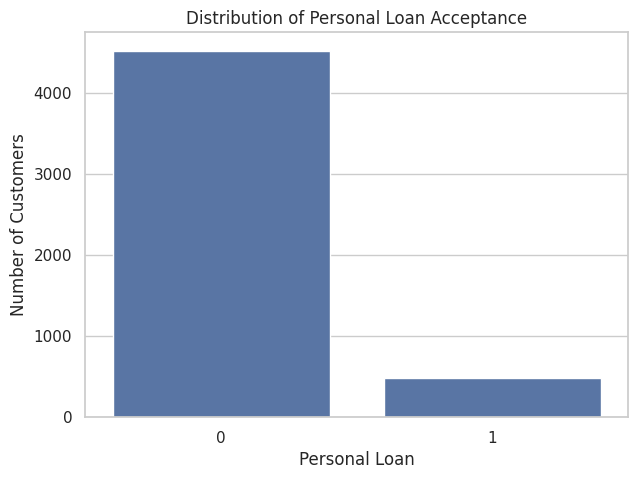

In [209]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Personal Loan")

plt.title("Distribution of Personal Loan Acceptance")
plt.xlabel("Personal Loan")
plt.ylabel("Number of Customers")

plt.show()

In [210]:
X = df.drop(columns=["ID", "Personal Loan"])
y = df["Personal Loan"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (5000, 12)
Target shape: (5000,)


In [211]:
print("Features used for prediction:")

for feature in X.columns:
    print("-", feature)

Features used for prediction:
- Age
- Experience
- Income
- ZIP Code
- Family
- CCAvg
- Education
- Mortgage
- Securities Account
- CD Account
- Online
- CreditCard


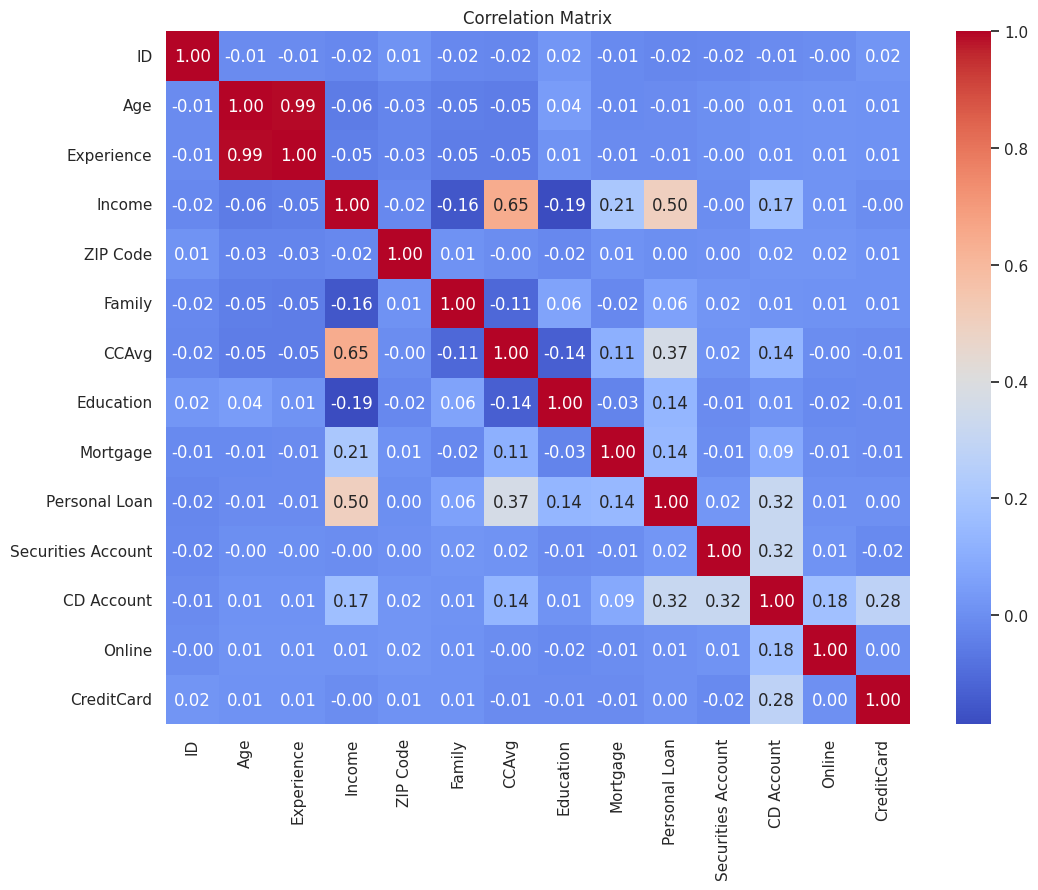

In [212]:
plt.figure(figsize=(12, 9))

correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

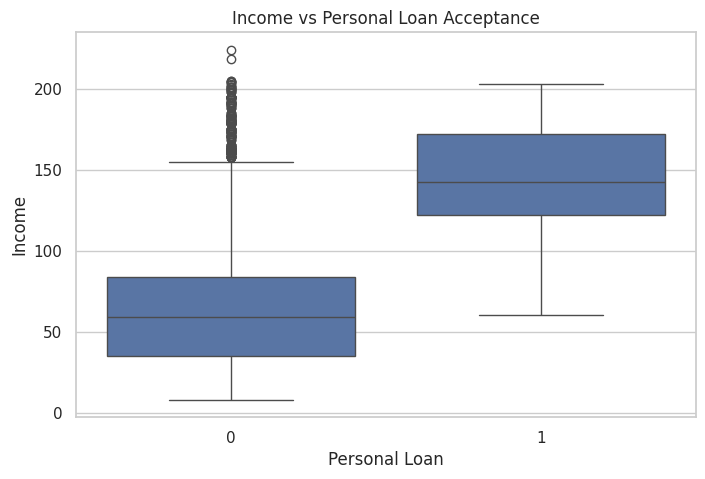

In [213]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Personal Loan",
    y="Income"
)

plt.title("Income vs Personal Loan Acceptance")
plt.xlabel("Personal Loan")
plt.ylabel("Income")

plt.show()

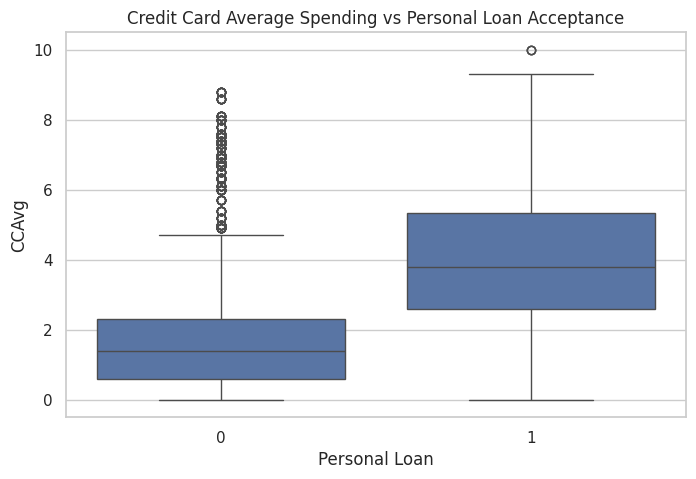

In [214]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Personal Loan",
    y="CCAvg"
)

plt.title("Credit Card Average Spending vs Personal Loan Acceptance")
plt.xlabel("Personal Loan")
plt.ylabel("CCAvg")

plt.show()

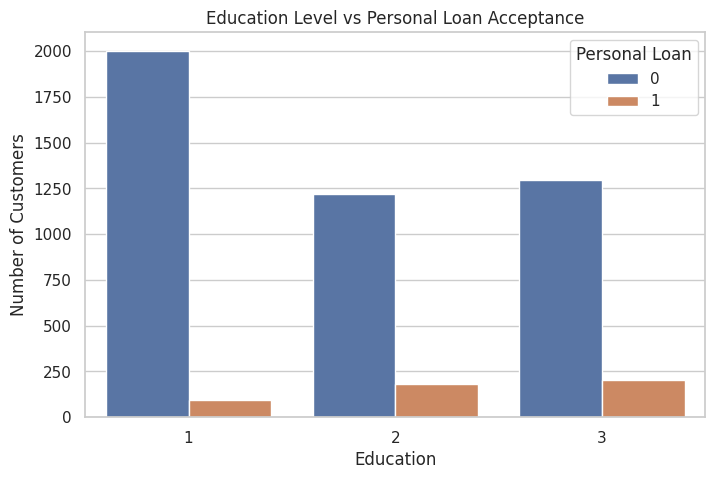

In [215]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Education",
    hue="Personal Loan"
)

plt.title("Education Level vs Personal Loan Acceptance")
plt.xlabel("Education")
plt.ylabel("Number of Customers")

plt.show()

In [216]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 4000
Testing samples: 1000


In [217]:
print("Training set distribution:")
print(y_train.value_counts())

print("\nTesting set distribution:")
print(y_test.value_counts())

Training set distribution:
Personal Loan
0    3616
1     384
Name: count, dtype: int64

Testing set distribution:
Personal Loan
0    904
1     96
Name: count, dtype: int64


In [218]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Feature scaling completed.
Training data shape: (4000, 12)
Testing data shape: (1000, 12)


In [219]:
# CELL 25 — Hyperparameter Tuning: Perceptron

perceptron_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Perceptron(random_state=42))
])

perceptron_param_grid_pipeline = {
    "model__penalty": [None, "l1", "l2", "elasticnet"],
    "model__alpha": [0.0001, 0.001, 0.01],
    "model__eta0": [0.01, 0.1],
    "model__max_iter": [1000, 2000]
}

perceptron_grid = GridSearchCV(
    estimator=perceptron_pipeline,
    param_grid=perceptron_param_grid_pipeline,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

perceptron_grid.fit(X_train, y_train)

print("Perceptron tuning completed.")

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Perceptron tuning completed.


In [220]:
# CELL 26 — Best Perceptron Parameters

print("Best Perceptron Parameters:")
print(perceptron_grid.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(perceptron_grid.best_score_)

Best Perceptron Parameters:
{'model__alpha': 0.0001, 'model__eta0': 0.01, 'model__max_iter': 1000, 'model__penalty': 'l1'}

Best Cross-Validation F1 Score:
0.6858456340142836


In [221]:
# CELL 27 — Best Perceptron Model

best_perceptron = perceptron_grid.best_estimator_

perceptron_pred = best_perceptron.predict(X_test)

perceptron_score = best_perceptron.decision_function(X_test)

print("Best Perceptron model selected.")

Best Perceptron model selected.


In [222]:
# CELL 28 — Perceptron Final Test Results

perceptron_accuracy = accuracy_score(y_test, perceptron_pred)
perceptron_precision = precision_score(
    y_test, perceptron_pred, zero_division=0
)
perceptron_recall = recall_score(
    y_test, perceptron_pred, zero_division=0
)
perceptron_f1 = f1_score(
    y_test, perceptron_pred, zero_division=0
)
perceptron_auc = roc_auc_score(
    y_test,perceptron_score
)

print("Perceptron — Test Set")
print("---------------------")
print("Accuracy :", round(perceptron_accuracy, 4))
print("Precision:", round(perceptron_precision, 4))
print("Recall   :", round(perceptron_recall, 4))
print("F1 Score :", round(perceptron_f1, 4))
print("ROC-AUC  :", round(perceptron_auc, 4))

Perceptron — Test Set
---------------------
Accuracy : 0.929
Precision: 0.6238
Recall   : 0.6562
F1 Score : 0.6396
ROC-AUC  : 0.94


In [223]:
# CELL 30 — Hyperparameter Tuning: Logistic Regression

logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        random_state=42,
        max_iter=2000
    ))
])

logistic_param_grid_pipeline = [
    {
        "model__penalty": ["l1"],
        "model__solver": ["liblinear"],
        "model__C": [0.01, 0.1, 1, 10, 100]
    },
    {
        "model__penalty": ["l2"],
        "model__solver": ["liblinear", "lbfgs"],
        "model__C": [0.01, 0.1, 1, 10, 100]
    }
]

logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid_pipeline,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

logistic_grid.fit(X_train, y_train)

print("Logistic Regression tuning completed.")

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Logistic Regression tuning completed.


In [224]:
# CELL 31 — Best Logistic Regression Parameters

print("Best Logistic Regression Parameters:")
print(logistic_grid.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(logistic_grid.best_score_)

Best Logistic Regression Parameters:
{'model__C': 1, 'model__penalty': 'l1', 'model__solver': 'liblinear'}

Best Cross-Validation F1 Score:
0.7128270227603772


In [225]:
# CELL 32 — Best Logistic Regression Model

best_logistic = logistic_grid.best_estimator_

logistic_pred = best_logistic.predict(X_test)

logistic_prob = best_logistic.predict_proba(X_test)[:, 1]

print("Best Logistic Regression model selected.")

Best Logistic Regression model selected.


In [226]:
# CELL 33 — Logistic Regression Final Test Results

logistic_accuracy = accuracy_score(y_test, logistic_pred)
logistic_precision = precision_score(y_test, logistic_pred)
logistic_recall = recall_score(y_test, logistic_pred)
logistic_f1 = f1_score(y_test, logistic_pred)
logistic_auc = roc_auc_score(y_test, logistic_prob)

print("Logistic Regression — Test Set")
print("--------------------------------")
print("Accuracy :", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall   :", round(logistic_recall, 4))
print("F1 Score :", round(logistic_f1, 4))
print("ROC-AUC  :", round(logistic_auc, 4))

Logistic Regression — Test Set
--------------------------------
Accuracy : 0.952
Precision: 0.8077
Recall   : 0.6562
F1 Score : 0.7241
ROC-AUC  : 0.9633


In [227]:
# CELL 35 — Hyperparameter Tuning: SVM

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        probability=True,
        random_state=42
    ))
])

svm_param_grid_pipeline = [
    {
        "model__kernel": ["linear"],
        "model__C": [0.01, 0.1, 1, 10, 100]
    },
    {
        "model__kernel": ["rbf"],
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", "auto", 0.001, 0.01, 0.1]
    },
    {
        "model__kernel": ["poly"],
        "model__C": [0.1, 1, 10],
        "model__degree": [2, 3, 4],
        "model__gamma": ["scale", "auto"]
    }
]

svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid_pipeline,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

svm_grid.fit(X_train, y_train)

print("SVM tuning completed.")

Fitting 5 folds for each of 43 candidates, totalling 215 fits
SVM tuning completed.


In [228]:
# CELL 36 — Best SVM Parameters

print("Best SVM Parameters:")
print(svm_grid.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(svm_grid.best_score_)

Best SVM Parameters:
{'model__C': 10, 'model__gamma': 0.1, 'model__kernel': 'rbf'}

Best Cross-Validation F1 Score:
0.8651780222464147


In [229]:
# CELL 37 — Best SVM Model

best_svm = svm_grid.best_estimator_

svm_pred = best_svm.predict(X_test)

svm_prob = best_svm.predict_proba(X_test)[:, 1]

print("Best SVM model selected.")

Best SVM model selected.


In [230]:
# CELL 38 — SVM Final Test Results

svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred)
svm_recall = recall_score(y_test, svm_pred)
svm_f1 = f1_score(y_test, svm_pred)
svm_auc = roc_auc_score(y_test, svm_prob)

print("SVM — Test Set")
print("---------------")
print("Accuracy :", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("F1 Score :", round(svm_f1, 4))
print("ROC-AUC  :", round(svm_auc, 4))

SVM — Test Set
---------------
Accuracy : 0.984
Precision: 0.9545
Recall   : 0.875
F1 Score : 0.913
ROC-AUC  : 0.9924


In [231]:
# CELL 40 — Hyperparameter Tuning: MLP

mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        solver="adam",
        max_iter=1000,
        random_state=42,
        early_stopping=True
    ))
])

mlp_param_grid_pipeline = {
    "model__hidden_layer_sizes": [
        (50,),
        (100,),
        (50, 50),
        (100, 50)
    ],
    "model__activation": ["relu", "tanh"],
    "model__alpha": [0.0001, 0.001, 0.01],
    "model__learning_rate": ["constant", "adaptive"],
    "model__learning_rate_init": [0.001, 0.01]
}

mlp_grid = GridSearchCV(
    estimator=mlp_pipeline,
    param_grid=mlp_param_grid_pipeline,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

mlp_grid.fit(X_train, y_train)

print("MLP tuning completed.")

Fitting 5 folds for each of 96 candidates, totalling 480 fits
MLP tuning completed.


In [232]:
# CELL 41 — Best MLP Parameters

print("Best MLP Parameters:")
print(mlp_grid.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(mlp_grid.best_score_)

Best MLP Parameters:
{'model__activation': 'tanh', 'model__alpha': 0.0001, 'model__hidden_layer_sizes': (100, 50), 'model__learning_rate': 'constant', 'model__learning_rate_init': 0.01}

Best Cross-Validation F1 Score:
0.8745863680728239


In [233]:
# CELL 42 — Best MLP Model

best_mlp = mlp_grid.best_estimator_

mlp_pred = best_mlp.predict(X_test)

mlp_prob = best_mlp.predict_proba(X_test)[:, 1]

print("Best MLP model selected.")

Best MLP model selected.


In [234]:
# CELL 43 — MLP Final Test Results

mlp_accuracy = accuracy_score(y_test, mlp_pred)
mlp_precision = precision_score(y_test, mlp_pred)
mlp_recall = recall_score(y_test, mlp_pred)
mlp_f1 = f1_score(y_test, mlp_pred)
mlp_auc = roc_auc_score(y_test, mlp_prob)

print("MLP — Test Set")
print("---------------")
print("Accuracy :", round(mlp_accuracy, 4))
print("Precision:", round(mlp_precision, 4))
print("Recall   :", round(mlp_recall, 4))
print("F1 Score :", round(mlp_f1, 4))
print("ROC-AUC  :", round(mlp_auc, 4))

MLP — Test Set
---------------
Accuracy : 0.987
Precision: 0.956
Recall   : 0.9062
F1 Score : 0.9305
ROC-AUC  : 0.993


In [235]:
# CELL 44 — K-Means Parameter Configurations

kmeans_param_grid = {
    "init": ["random", "k-means++"],
    "n_init": [1, 10, 20],
    "max_iter": [100, 300, 500],
    "tol": [1e-4, 1e-3, 1e-2]
}

print("K-Means parameter grid created.")

K-Means parameter grid created.


In [236]:
# CELL 45 — K-Means Hyperparameter Tuning Function

def evaluate_kmeans_parameters(X_data, y_data, params, cv=5):

    skf = StratifiedKFold(
        n_splits=cv,
        shuffle=True,
        random_state=42
    )

    fold_f1_scores = []

    for train_idx, val_idx in skf.split(X_data, y_data):

        # Split the current CV fold
        X_cv_train = X_data.iloc[train_idx]
        X_cv_val = X_data.iloc[val_idx]

        y_cv_train = y_data.iloc[train_idx]
        y_cv_val = y_data.iloc[val_idx]

        # Fit scaler ONLY on the CV training fold
        cv_scaler = StandardScaler()

        X_cv_train_scaled = cv_scaler.fit_transform(
            X_cv_train
        )

        X_cv_val_scaled = cv_scaler.transform(
            X_cv_val
        )

        # Train K-Means
        model = KMeans(
            n_clusters=2,
            random_state=42,
            **params
        )

        model.fit(X_cv_train_scaled)

        # Get cluster assignments
        train_clusters = model.predict(
            X_cv_train_scaled
        )

        val_clusters = model.predict(
            X_cv_val_scaled
        )

        # Calculate acceptance rate for each cluster
        cluster_acceptance_rates = {}

        for cluster in [0, 1]:

            cluster_targets = y_cv_train[
                train_clusters == cluster
            ]

            if len(cluster_targets) > 0:
                cluster_acceptance_rates[cluster] = (
                    cluster_targets.mean()
                )
            else:
                cluster_acceptance_rates[cluster] = 0

        # Cluster with higher acceptance rate = class 1
        positive_cluster = max(
            cluster_acceptance_rates,
            key=cluster_acceptance_rates.get
        )

        negative_cluster = 1 - positive_cluster

        mapping = {
            negative_cluster: 0,
            positive_cluster: 1
        }

        # Convert clusters to binary predictions
        val_predictions = np.array([
            mapping[cluster]
            for cluster in val_clusters
        ])

        # Calculate F1
        fold_f1 = f1_score(
            y_cv_val,
            val_predictions,
            zero_division=0
        )

        fold_f1_scores.append(fold_f1)

    return np.mean(fold_f1_scores)

In [237]:
# CELL 46 — Perform K-Means Hyperparameter Tuning

kmeans_results = []

parameter_names = list(kmeans_param_grid.keys())

parameter_values = [
    kmeans_param_grid[name]
    for name in parameter_names
]

all_combinations = list(
    product(*parameter_values)
)

print(
    "Total K-Means configurations:",
    len(all_combinations)
)

X_train_kmeans = X_train.reset_index(drop=True)
y_train_kmeans = y_train.reset_index(drop=True)

for combination in all_combinations:

    params = dict(
        zip(parameter_names, combination)
    )

    mean_f1 = evaluate_kmeans_parameters(
        X_train_kmeans,
        y_train_kmeans,
        params,
        cv=5
    )

    kmeans_results.append({
        **params,
        "mean_cv_f1": mean_f1
    })

print("K-Means tuning completed.")

Total K-Means configurations: 54
K-Means tuning completed.


In [238]:
# CELL 47 — Best K-Means Parameters

kmeans_results_df = pd.DataFrame(kmeans_results)

kmeans_results_df = kmeans_results_df.sort_values(
    by="mean_cv_f1",
    ascending=False
)

print("Best K-Means configuration:")
display(kmeans_results_df.head(1))

Best K-Means configuration:


,init,n_init,max_iter,tol,mean_cv_f1
5,random,1,300,0.01,0.372108


In [239]:
# CELL 48 — Train Best K-Means Model

best_kmeans_params = {
    "init": kmeans_results_df.iloc[0]["init"],
    "n_init": int(kmeans_results_df.iloc[0]["n_init"]),
    "max_iter": int(kmeans_results_df.iloc[0]["max_iter"]),
    "tol": float(kmeans_results_df.iloc[0]["tol"])
}

best_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    **best_kmeans_params
)

best_kmeans.fit(X_train_scaled)

print("Best K-Means model trained.")
print("Parameters:", best_kmeans_params)

Best K-Means model trained.
Parameters: {'init': 'random', 'n_init': 1, 'max_iter': 300, 'tol': 0.01}


In [240]:
# CELL 49 — Map K-Means Clusters to Loan Classes

kmeans_train_clusters = best_kmeans.predict(X_train_scaled)
kmeans_test_clusters = best_kmeans.predict(X_test_scaled)

# Calculate the acceptance rate in each cluster
cluster_acceptance_rates = {}

for cluster in [0, 1]:

    cluster_targets = y_train[
        kmeans_train_clusters == cluster
    ]

    acceptance_rate = cluster_targets.mean()

    cluster_acceptance_rates[cluster] = acceptance_rate

print("Loan acceptance rate in each cluster:")

for cluster, rate in cluster_acceptance_rates.items():
    print(
        f"Cluster {cluster}: "
        f"{rate:.4f} ({rate * 100:.2f}%)"
    )

# The cluster with the higher acceptance rate
# is treated as the "Personal Loan = 1" cluster.

positive_cluster = max(
    cluster_acceptance_rates,
    key=cluster_acceptance_rates.get
)

negative_cluster = 1 - positive_cluster

cluster_mapping = {
    negative_cluster: 0,
    positive_cluster: 1
}

print("\nCluster-to-class mapping:")
print(cluster_mapping)

Loan acceptance rate in each cluster:
Cluster 0: 0.0293 (2.93%)
Cluster 1: 0.3263 (32.63%)

Cluster-to-class mapping:
{0: 0, 1: 1}


In [241]:
# CELL 50 — Generate K-Means Predictions

kmeans_pred = np.array([
    cluster_mapping[cluster]
    for cluster in kmeans_test_clusters
])

print("K-Means predictions generated.")

print("\nPredicted class distribution:")
print(pd.Series(kmeans_pred).value_counts())

K-Means predictions generated.

Predicted class distribution:
0    768
1    232
Name: count, dtype: int64


In [242]:
# CELL 50A — K-Means Continuous Score for ROC-AUC

# Get distances from every test point to both cluster centroids
kmeans_distances = best_kmeans.transform(X_test_scaled)

# Distance to the cluster associated with Personal Loan = 1
positive_cluster_distance = kmeans_distances[:, positive_cluster]

# Distance to the cluster associated with Personal Loan = 0
negative_cluster_distance = kmeans_distances[:, negative_cluster]

# Convert distances into a continuous score.
# Higher score = stronger association with the positive cluster.
kmeans_score = (
    negative_cluster_distance
    - positive_cluster_distance
)

print("K-Means continuous scores generated.")
print("Score range:",
      round(kmeans_score.min(), 4),
      "to",
      round(kmeans_score.max(), 4))

K-Means continuous scores generated.
Score range: -2.2877 to 2.0695


In [243]:
# CELL 51 — K-Means Final Test Results

kmeans_accuracy = accuracy_score(y_test,kmeans_pred)
kmeans_precision = precision_score(y_test,kmeans_pred,zero_division=0)
kmeans_recall = recall_score(y_test,kmeans_pred,zero_division=0)
kmeans_f1 = f1_score(y_test,kmeans_pred,zero_division=0)
kmeans_auc = roc_auc_score(y_test,kmeans_score)

print("K-Means — Test Set")
print("-------------------")
print("Accuracy :", round(kmeans_accuracy, 4))
print("Precision:", round(kmeans_precision, 4))
print("Recall   :", round(kmeans_recall, 4))
print("F1 Score :", round(kmeans_f1, 4))
print("K-Means ROC-AUC:", round(kmeans_auc, 4))

K-Means — Test Set
-------------------
Accuracy : 0.83
Precision: 0.3405
Recall   : 0.8229
F1 Score : 0.4817
K-Means ROC-AUC: 0.8888


In [244]:
# CELL 52 — Create Final Results Table

results = pd.DataFrame({
    "Model": [
        "Perceptron",
        "Logistic Regression",
        "SVM",
        "MLP",
        "K-Means"
    ],

    "Accuracy": [
        perceptron_accuracy,
        logistic_accuracy,
        svm_accuracy,
        mlp_accuracy,
        kmeans_accuracy
    ],

    "Precision": [
        perceptron_precision,
        logistic_precision,
        svm_precision,
        mlp_precision,
        kmeans_precision
    ],

    "Recall": [
        perceptron_recall,
        logistic_recall,
        svm_recall,
        mlp_recall,
        kmeans_recall
    ],

    "F1 Score": [
        perceptron_f1,
        logistic_f1,
        svm_f1,
        mlp_f1,
        kmeans_f1
    ],

    "ROC-AUC": [
        perceptron_auc,
        logistic_auc,
        svm_auc,
        mlp_auc,
        kmeans_auc
    ]
})

print("Final Model Comparison")
print("======================")

display(results.round(4))

Final Model Comparison


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Perceptron,0.929,0.6238,0.6562,0.6396,0.9400
1,Logistic Regression,0.952,0.8077,0.6562,0.7241,0.9633
2,SVM,0.984,0.9545,0.8750,0.9130,0.9924
3,MLP,0.987,0.9560,0.9062,0.9305,0.9930
4,K-Means,0.830,0.3405,0.8229,0.4817,0.8888


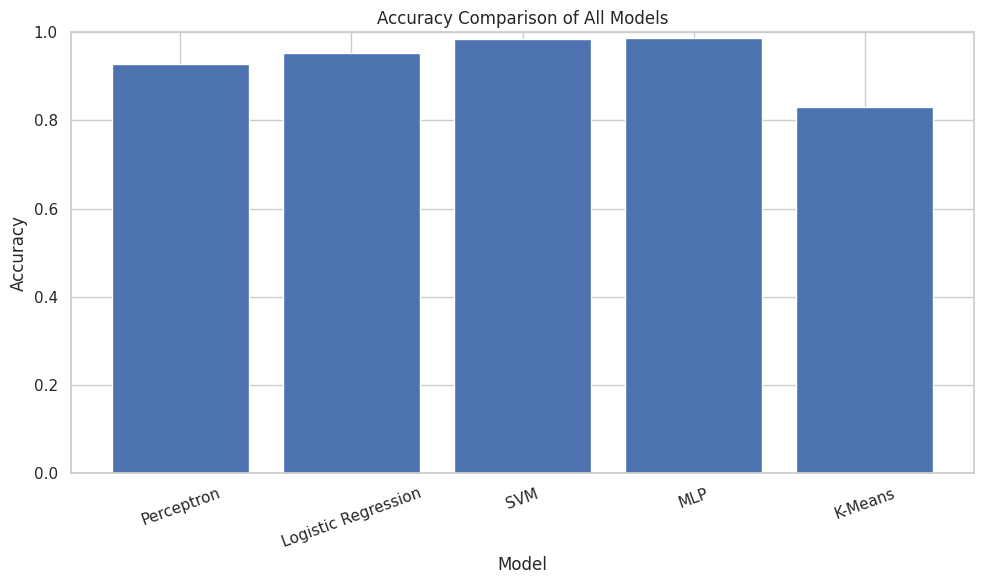

In [245]:
# CELL 53 — Accuracy Comparison

plt.figure(figsize=(10, 6))

plt.bar(results["Model"], results["Accuracy"])

plt.title("Accuracy Comparison of All Models")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

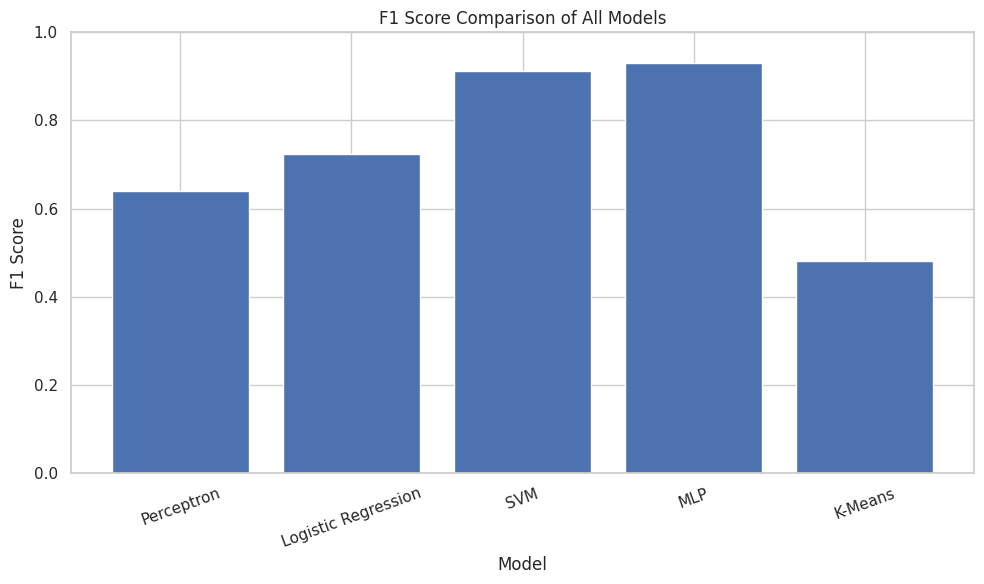

In [246]:
# CELL 54 — F1 Score Comparison

plt.figure(figsize=(10, 6))

plt.bar(results["Model"], results["F1 Score"])

plt.title("F1 Score Comparison of All Models")
plt.xlabel("Model")
plt.ylabel("F1 Score")
plt.ylim(0, 1)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

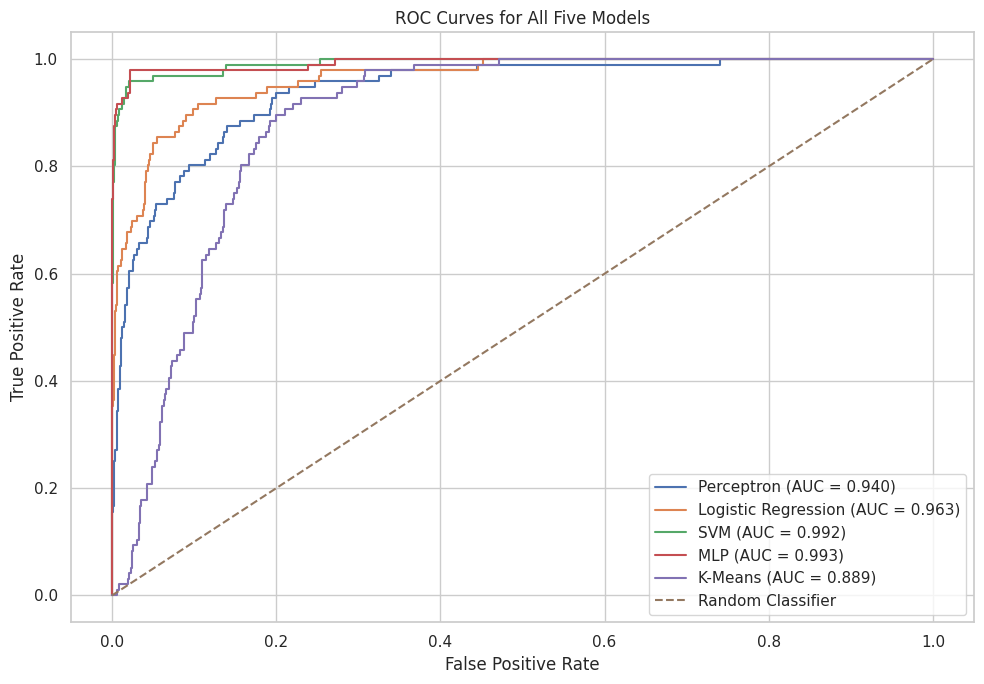

In [247]:
# CELL 55 — Combined ROC Curve for All Five Models

model_scores = {
    "Perceptron": perceptron_score,
    "Logistic Regression": logistic_prob,
    "SVM": svm_prob,
    "MLP": mlp_prob,
    "K-Means": kmeans_score
}

plt.figure(figsize=(10, 7))

for model_name, scores in model_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc_value = roc_auc_score(y_test, scores)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random Classifier"
)

plt.title("ROC Curves for All Five Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

In [248]:
# CELL 56 — ROC-AUC Comparison

auc_results = results[["Model", "ROC-AUC"]].copy()

print("ROC-AUC Comparison")
print("==================")

display(auc_results.round(4))

ROC-AUC Comparison


,Model,ROC-AUC
0,Perceptron,0.9400
1,Logistic Regression,0.9633
2,SVM,0.9924
3,MLP,0.9930
4,K-Means,0.8888


In [249]:
# CELL 57 — Classification Reports

print("PERCEPTRON")
print("===========")
print(classification_report(y_test, perceptron_pred, zero_division=0))

print("\nLOGISTIC REGRESSION")
print("===================")
print(classification_report(y_test, logistic_pred, zero_division=0))

print("\nSVM")
print("===")
print(classification_report(y_test, svm_pred, zero_division=0))

print("\nMLP")
print("===")
print(classification_report(y_test, mlp_pred, zero_division=0))

print("\nK-MEANS")
print("=======")
print(classification_report(y_test, kmeans_pred, zero_division=0))

PERCEPTRON
              precision    recall  f1-score   support

           0       0.96      0.96      0.96       904
           1       0.62      0.66      0.64        96

    accuracy                           0.93      1000
   macro avg       0.79      0.81      0.80      1000
weighted avg       0.93      0.93      0.93      1000


LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       904
           1       0.81      0.66      0.72        96

    accuracy                           0.95      1000
   macro avg       0.89      0.82      0.85      1000
weighted avg       0.95      0.95      0.95      1000


SVM
===
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       904
           1       0.95      0.88      0.91        96

    accuracy                           0.98      1000
   macro avg       0.97      0.94      0.95      1000
weighted avg       0.98      0.98

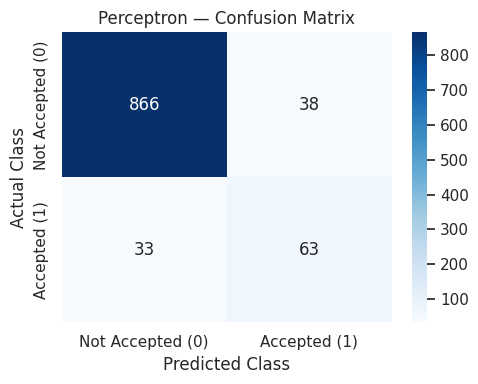

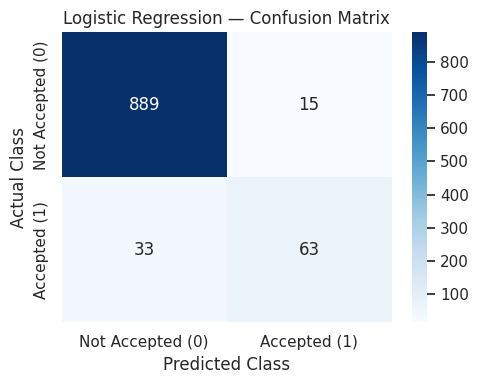

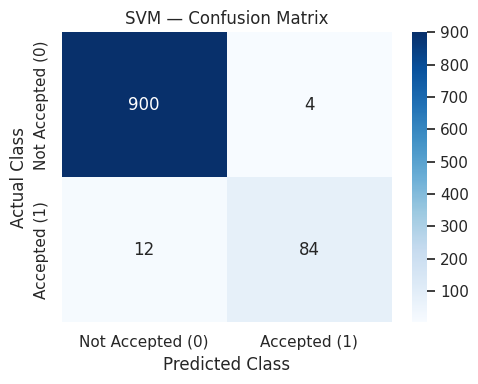

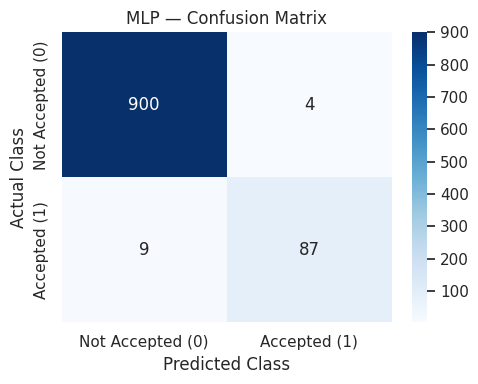

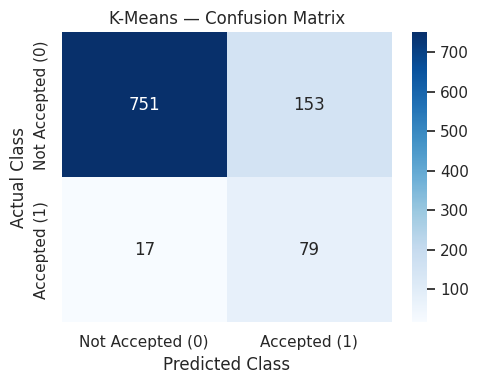

In [250]:
# CELL 58 — Confusion Matrix Heatmaps

models = {
    "Perceptron": (y_test, perceptron_pred),
    "Logistic Regression": (y_test, logistic_pred),
    "SVM": (y_test, svm_pred),
    "MLP": (y_test, mlp_pred),
    "K-Means": (y_test, kmeans_pred)
}

for model_name, (y_true, y_pred) in models.items():

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Accepted (0)", "Accepted (1)"],
        yticklabels=["Not Accepted (0)", "Accepted (1)"]
    )

    plt.title(f"{model_name} — Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.tight_layout()
    plt.show()

In [251]:
# CELL 59 — Best Hyperparameters Summary

print("BEST HYPERPARAMETERS")
print("====================")

print("\nPerceptron:")
for key, value in perceptron_grid.best_params_.items():
    print(key.replace("model__", ""), ":", value)

print("\nLogistic Regression:")
for key, value in logistic_grid.best_params_.items():
    print(key.replace("model__", ""), ":", value)

print("\nSVM:")
for key, value in svm_grid.best_params_.items():
    print(key.replace("model__", ""), ":", value)

print("\nMLP:")
for key, value in mlp_grid.best_params_.items():
    print(key.replace("model__", ""), ":", value)

print("\nK-Means:")
print({
    "init": best_kmeans.get_params()["init"],
    "n_init": best_kmeans.get_params()["n_init"],
    "max_iter": best_kmeans.get_params()["max_iter"],
    "tol": best_kmeans.get_params()["tol"]
})

BEST HYPERPARAMETERS

Perceptron:
alpha : 0.0001
eta0 : 0.01
max_iter : 1000
penalty : l1

Logistic Regression:
C : 1
penalty : l1
solver : liblinear

SVM:
C : 10
gamma : 0.1
kernel : rbf

MLP:
activation : tanh
alpha : 0.0001
hidden_layer_sizes : (100, 50)
learning_rate : constant
learning_rate_init : 0.01

K-Means:
{'init': 'random', 'n_init': 1, 'max_iter': 300, 'tol': 0.01}
